# Sign-language project: workflow, decisions and investigation



    This notebook records implemented work, experimental evidence, unsuccessful
    checks and remaining limitations. It is a read-only report: Run All reads
    the companion snapshot and redraws figures; it never starts training.
    Figures/tables are embedded, so the saved notebook is readable without videos,
    landmark archives, checkpoints or a running kernel. Rerunning needs Python,
    NumPy and Matplotlib (plus an IPython kernel in a notebook editor).

    Training/program code remains in ordinary Python modules. The notebook is a
    research record, not a second implementation. For detailed actions see the
    [investigation log](../docs/recognition-investigation-2026-11-10.md) and
    [project summary](../sign_language_project_summary.md).

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt

def find_snapshot():
    for folder in (Path.cwd(), *Path.cwd().parents):
        for relative in ('artifacts/experiment_snapshot.json', 'notebooks/artifacts/experiment_snapshot.json'):
            candidate = folder/relative
            if candidate.exists():
                return candidate
    raise FileNotFoundError('Keep the notebooks/artifacts folder beside these notebooks.')

SNAPSHOT_PATH = find_snapshot()
S = json.loads(SNAPSHOT_PATH.read_text(encoding='utf-8'))
M = S['models']
COLORS = {'gru_baseline':'#2878b5','gru_regularized':'#219653','gru64':'#e49320','stgcn':'#8e44ad'}
plt.rcParams.update({'figure.figsize':(11,5),'font.size':10,'axes.spines.top':False,
                     'axes.spines.right':False,'axes.grid':True,'grid.alpha':.18,
                     'figure.constrained_layout.use':True})
def finish(title):
    plt.gcf().suptitle(title,fontsize=14,fontweight='bold')
    plt.show()
print('Snapshot:',S['generated_utc'])
print('ST-GCN final evaluation complete:',S['stgcn_complete'])
print('Read-only report: no training, extraction, downloads, webcam or weight updates.')

Snapshot: 2026-11-10T20:33:21.779173+00:00
ST-GCN final evaluation complete: True
Read-only report: no training, extraction, downloads, webcam or weight updates.


## 1. Scope and implementation history

    - Goal: one isolated ASL sign from a webcam clip → its text/gloss. Continuous
      signing and sentence generation are future work.
    - Earlier WLASL/SVM/I3D experiments were removed at the user's request.
      They are historical experiments, not active fallback models. Their
      unpreserved measurements are not invented or included as comparable scores.
    - ASL now uses Microsoft ASL Citizen. Slovo is selected for a separate RSL
      extension; its landmark/schema audit and RSL training are still pending.
    - Repository setup was simplified to one project environment using uv;
      the initially added CI pipeline was removed at the user's request.
    - Work progressed through dataset auditing, MediaPipe hand preview,
      CPU/GPU extraction diagnostics, resumable full extraction, normalization,
      GRU baselines/CV, held-out testing, webcam diagnosis and the ST-GCN comparison.

    Sources: [ASL Citizen](https://www.microsoft.com/en-us/research/project/asl-citizen/),
    [ASL Citizen code](https://github.com/microsoft/ASL-citizen-code),
    [Slovo](https://github.com/hukenovs/slovo),
    [decisions](../docs/project-decisions.md).

## 2. Dataset and split audit

    Keep official signer-disjoint splits; random clip-level 80/20 splitting can
    mix signers. Train selects parameters, validation selects the checkpoint,
    and frozen test evaluation measures performance on additional held-out signers.
    These are ASL classification results, not RSL or webcam accuracy.

Microsoft ASL Citizen | 83399 videos | 2731 labels
train: 40,154 clips; 35 signers
  val: 10,304 clips; 6 signers
 test: 32,941 clips; 11 signers


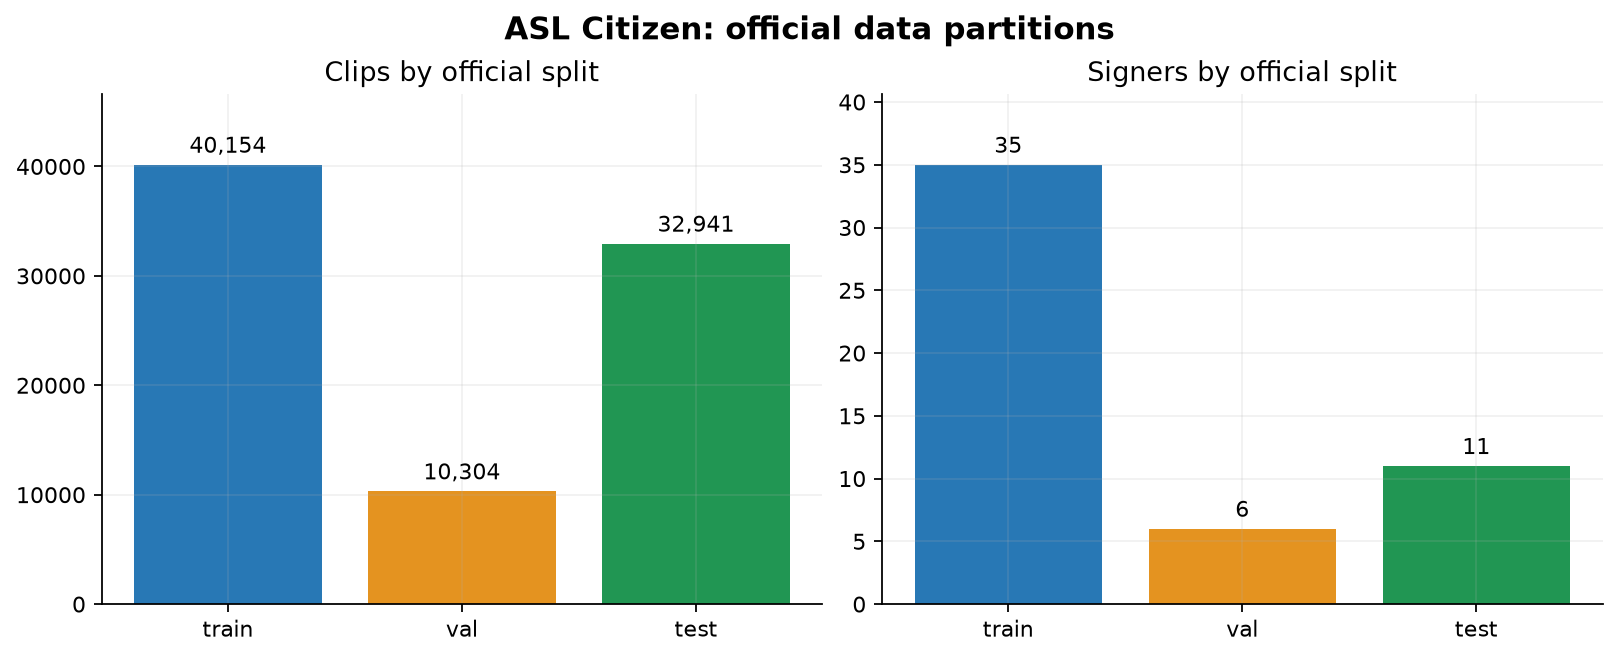

In [2]:
d=S['dataset']
print(d['name'], '|',d['total_clips'],'videos |',d['classes'],'labels')
for split,count in d['splits'].items():
    print(f'{split:>5}: {count:>6,} clips; {d["signers"][split]} signers')
fig,axs=plt.subplots(1,2,figsize=(10,4))
for ax,key,title in zip(axs,('splits','signers'),('Clips by official split','Signers by official split')):
    values=list(d[key].values())
    bars=ax.bar(list(d[key]),values,color=['#2878b5','#e49320','#219653'])
    ax.bar_label(bars,labels=[f'{x:,}' for x in values],padding=3)
    ax.set_title(title);ax.set_ylim(0,max(values)*1.16)
finish('ASL Citizen: official data partitions')

## 3. MediaPipe extraction and recovery

    MediaPipe's pretrained hand/pose models detect landmarks; they do not classify
    the word. Local extraction used CPU hand and pose-lite detectors and retained
    decoded frames, timestamps, handedness and missing/confidence masks in
    checksummed NPZ/ZIP shards. Completed shards survive worker-count changes.
    A hidden supervisor, duplicate-writer lock, atomic shard markers and bounded
    recovery were added after worker-pool crashes. The final selected count was
    two workers. Crash mitigation was not claimed as a proven native root-cause fix.

    Colab multiprocessing/GPU/EGL diagnostics were also investigated. GPU inference
    became possible, but tensor-write errors and coordinate disagreements prevented
    that extraction path from being adopted. CUDA GRU/ST-GCN training is separate
    from the MediaPipe GPU-delegate experiment.

    The local benchmark used the same 100 clips/9,257 frames for every setting.
    Its full-corpus hours are **extrapolations**, not measured completion durations.
    The extractor's last-session elapsed time is not a full-corpus wall time.
    [Extraction guide](../docs/landmark-extraction.md),
    [local benchmark](../docs/local-cpu-benchmark-2026-11-07.md),
    [job recovery/controls](../docs/local-extraction.md).

Extraction status: complete
Successful clips: 83399 | failures: 0
Shards: 836 | archive GiB: 5.004


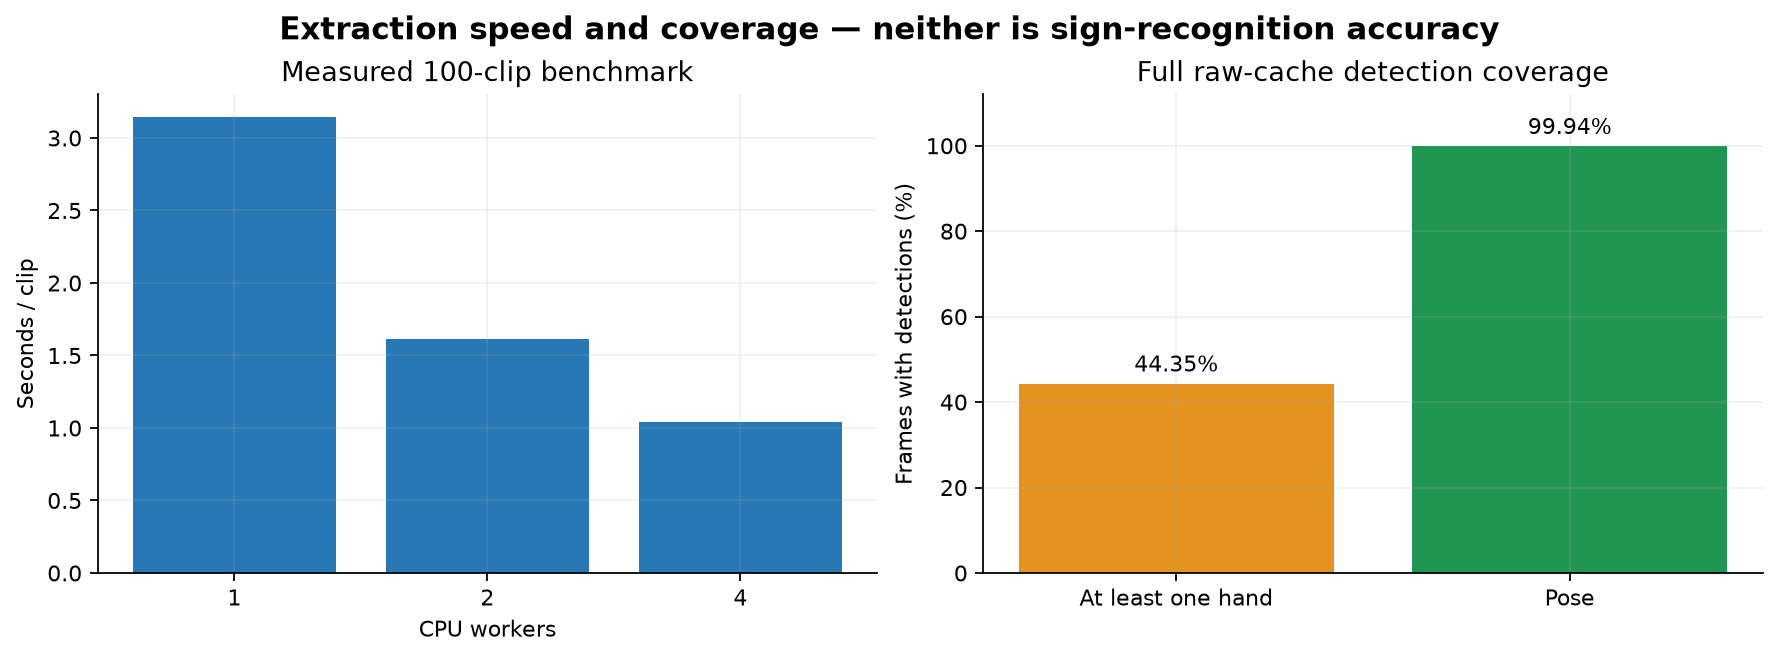

In [3]:
e=S['extraction'];b=S['cpu_benchmark']
print('Extraction status:',e.get('status'))
print('Successful clips:',e.get('successful_clips'),'| failures:',e.get('failed_clips'))
print('Shards:',e.get('completed_shards'),'| archive GiB:',round(e.get('feature_archive_bytes',0)/2**30,3))
fig,axs=plt.subplots(1,2,figsize=(11,4))
axs[0].bar([str(x) for x in b['workers']],b['seconds_per_clip'],color='#2878b5')
axs[0].set(xlabel='CPU workers',ylabel='Seconds / clip',title='Measured 100-clip benchmark')
total=e.get('decoded_frames',1)
values=[100*e.get('frames_with_hands',0)/total,100*e.get('frames_with_pose',0)/total]
bars=axs[1].bar(['At least one hand','Pose'],values,color=['#e49320','#219653'])
axs[1].bar_label(bars,labels=[f'{x:.2f}%' for x in values],padding=3)
axs[1].set(ylabel='Frames with detections (%)',ylim=(0,112),title='Full raw-cache detection coverage')
finish('Extraction speed and coverage — neither is sign-recognition accuracy')

## 4. Normalization and sequence construction

    Raw detector hand slots are not stable anatomical identities. Preprocessing
    uses pose wrists, handedness scores and short-term continuity to assign them.
    XY coordinates are aspect-corrected, centered at shoulders and divided by a
    clip-level median shoulder width. Hand-shape XYZ is additionally wrist-relative
    and palm-normalized; hand and pose depth are not fused into metric 3D.
    Missingness is explicit; only short internal anchor gaps are interpolated.

    Long signs are sampled across the **whole** clip to 128 ordered frames;
    shorter signs retain true lengths with right padding. The GRU uses packed
    sequences. ST-GCN masks temporal padding at every block and during pooling.

    | GRU feature group | Dimensions |
    | --- | ---: |
    | 13 pose joints × XY | 26 |
    | Pose-valid masks | 13 |
    | Two hands × 21 joints × body-relative XY | 84 |
    | Two hands × 21 joints × local XYZ | 126 |
    | Hand present / local-valid / body-anchor flags | 2 + 2 + 1 |
    | Total | **254** |

    ST-GCN selects seven pose points and ten points per hand from the existing
    body-relative XY cache. Its graph input is `[batch,2,128,27]`; no new landmark
    extraction was needed. The different node/channel representation means this
    is a **model-plus-input comparison**, not an isolated layer replacement.
    [Preprocessor](../src/sign_language/preprocessing.py),
    [graph adapter](../src/sign_language/stgcn_graph.py).

In [4]:
assert sum([26,13,84,126,2,2,1])==254
print('Prepared-cache identity:',S['cache']['cache_id'])
print('Preprocessing:',S['cache']['identity']['preprocessing']['version'])
for key,m in M.items():
    print(m['label'],':',m['config']['model'],'|',m['parameters'],'parameters')

Prepared-cache identity: 02d3e309c45ede4ef45209f8bd99b1f56d5c790fbaa2a7c9f26369d19dacde8a
Preprocessing: asl-body-local-hands-v1
GRU 256 baseline : {'input_size': 254, 'hidden_size': 256, 'layers': 2, 'classes': 2731, 'dropout': 0.3} | 1489835 parameters
GRU 256 regularized : {'input_size': 254, 'hidden_size': 256, 'layers': 2, 'classes': 2731, 'dropout': 0.5} | 1489835 parameters
GRU 64 baseline : {'input_size': 254, 'hidden_size': 64, 'layers': 2, 'classes': 2731, 'dropout': 0.3} | 263915 parameters
ST-GCN27 : {'classes': 2731, 'dropout': 0.5} | 3788165 parameters


## 5. Model experiments and evidence boundaries

    1. Two-layer 256-unit GRU baseline; checkpoint selected by validation loss.
    2. Three-fold signer-grouped development CV within the official train split,
       then a fresh regularized official-split refit. Dropout, weight decay and
       geometric augmentation changed together; their separate effects were not isolated.
    3. A 64-unit comparison using original baseline settings; its lower training
       and validation scores do not establish better generalization.
    4. Frozen official test evaluation of the regularized GRU.
    5. A separately trained ST-GCN27 with graph/temporal convolutions and pooling.

    Earlier ordinary-PyTorch cuDNN GRU shutdown crashes were isolated; the working
    GRU uses ATen CUDA with cuDNN disabled. ST-GCN convolutional cuDNN passed a
    separate forward/backward/save/reload/exit smoke test. Both train on the GPU.
    All weights/checkpoints remain in separate experiment folders.
    The second notebook plots these experiments from their saved epoch JSONs.

    One training update follows this sequence (illustrative summary, not executed):

    ```python
    optimizer.zero_grad(set_to_none=True)
    logits = model(prepared_sequences, true_lengths)
    loss = cross_entropy(logits, target_class_ids)
    scaler.scale(loss).backward()
    scaler.unscale_(optimizer)
    clip_grad_norm_(model.parameters(), 1.0)
    scaler.step(optimizer)
    scaler.update()
    ```

    AMP overflow handling skips unsafe updates. Validation disables gradients,
    dropout and augmentation. A scheduler responds to validation loss. Atomic
    `last.pt` stores optimizer/scaler/scheduler/RNG state for resume; `best.pt`
    stores the selected model, labels and configuration. Test evaluation uses
    `eval()` plus inference mode and verifies that the checkpoint is unchanged.

    Implementations: [GRU](../src/sign_language/gru_model.py),
    [GRU trainer](../src/sign_language/training.py),
    [ST-GCN](../src/sign_language/stgcn_model.py),
    [ST-GCN trainer](../src/sign_language/stgcn_training.py),
    [frozen evaluation](../src/sign_language/evaluation.py).
    Commands are documented in the linked guides; they are not executed by Run All.

### Completed ST-GCN result

        Training stopped after **49 epochs**. The selected
        checkpoint is **epoch 39**, using minimum
        validation cross-entropy. On all **32,941 test clips** it
        achieved **57.25% top-1**, **82.32%
        top-5**, and **56.74% macro F1**. Top-1 improved
        by **7.33 percentage points** over the regularized GRU overall.
        Some individual signs regressed; notebook 02 includes paired class
        comparisons. ST-GCN webcam performance has not been evaluated.

## 6. GRU webcam failure investigation

    These live checks used the regularized GRU; they are not ST-GCN webcam tests.
    The user reported THANKYOU→FROWN1, HELLO→NONSENSE and NO→THUNDER. A subsequent
    user-confirmed six-trial check tested the same captures under predefined
    timing windows and actual image reflection. No videos, landmark arrays or
    feature vectors were saved. Every variant had zero top-one and top-five
    matches on those six trials; this is one signer's diagnostic, not a general
    webcam-accuracy estimate.

    Checks found matching model/label/cache/detector identities and six exact
    fresh-video reproductions. Ordinary AMP/batch differences were negligible.
    The strongest supported weakness was hand-visibility/rest-context sensitivity;
    detector failures and smaller hand images contributed additional evidence.
    Their individual causal contributions were not uniquely separated.

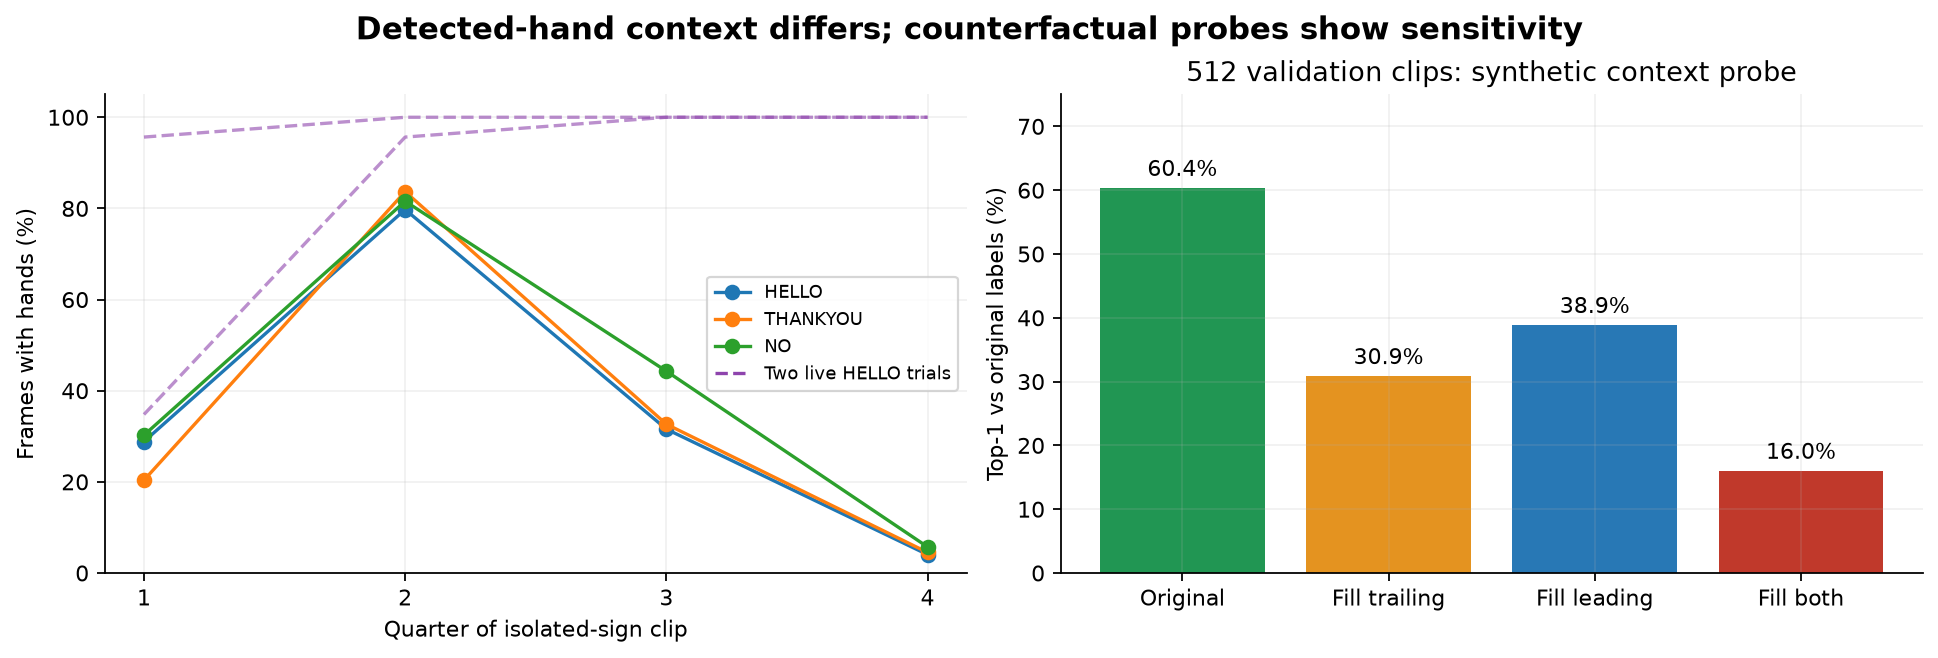

In [5]:
investigation=S['investigation']
fig,axs=plt.subplots(1,2,figsize=(12,4))
quarters=investigation['training_mean_hand_presence_by_quarter']
for name,values in quarters.items():axs[0].plot(range(1,5),np.array(values)*100,'o-',label=name)
live=investigation['live_input_comparisons']
for row in live:
    if row['expected']=='HELLO':axs[0].plot(range(1,5),np.array(row['hand_presence_by_quarter'])*100,'--',alpha=.6,color='#8e44ad')
axs[0].plot([],[],'--',color='#8e44ad',label='Two live HELLO trials')
axs[0].set(xlabel='Quarter of isolated-sign clip',ylabel='Frames with hands (%)',xticks=[1,2,3,4],ylim=(0,105))
axs[0].legend(fontsize=8)
modes=['original','fill_tail_hand_context','fill_head_hand_context','fill_both_hand_context']
values=[investigation['validation_sample_perturbations'][x]['top1']*100 for x in modes]
bars=axs[1].bar(['Original','Fill trailing','Fill leading','Fill both'],values,color=['#219653','#e49320','#2878b5','#c0392b'])
axs[1].bar_label(bars,fmt='%.1f%%',padding=3)
axs[1].set(ylabel='Top-1 vs original labels (%)',ylim=(0,75),title='512 validation clips: synthetic context probe')
finish('Detected-hand context differs; counterfactual probes show sensitivity')

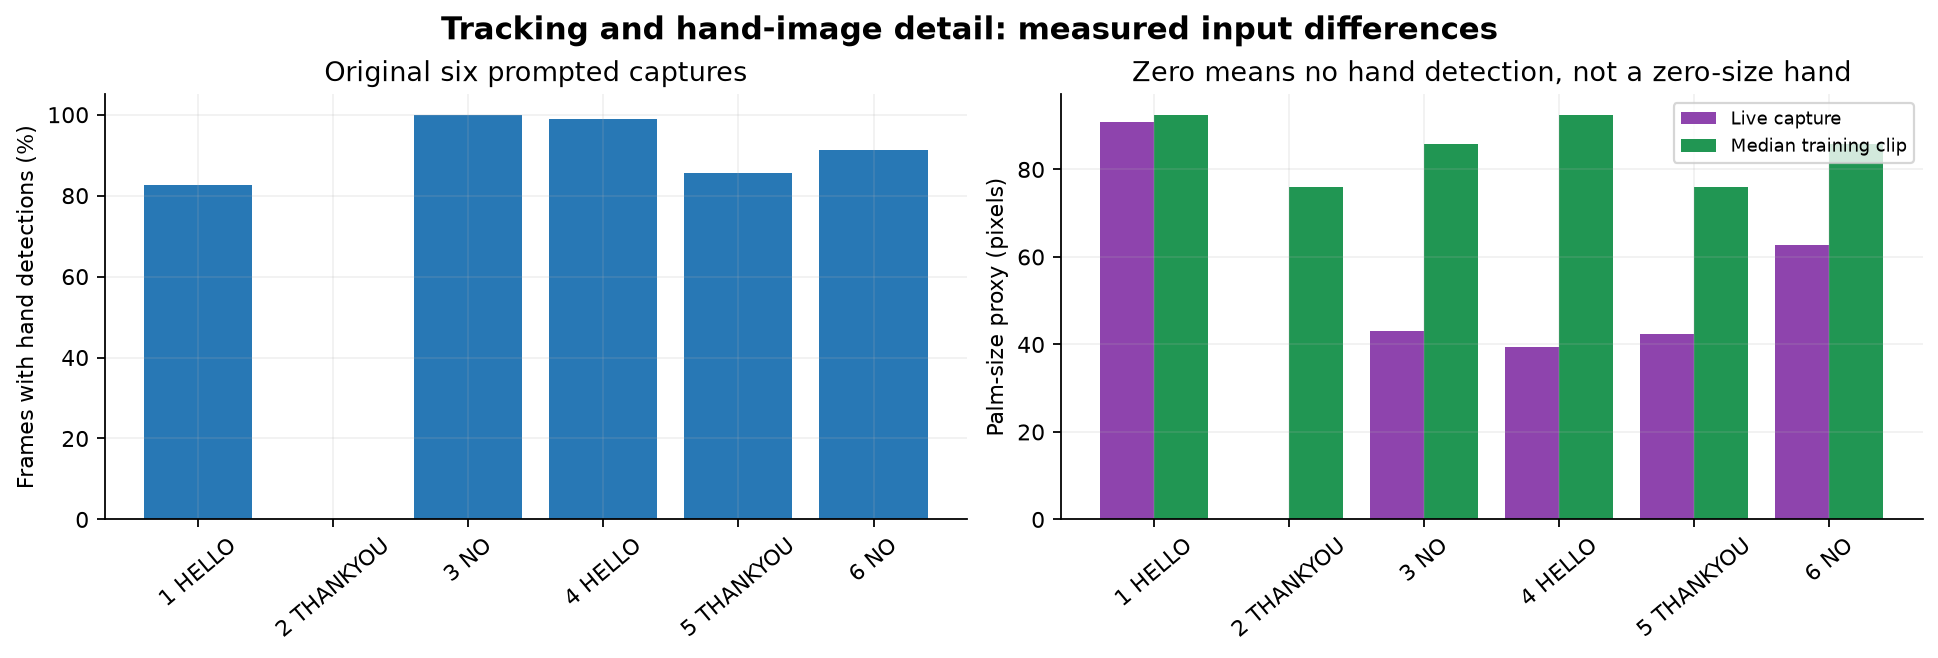

In [6]:
rows=investigation['live_input_comparisons']
names=[f"{i+1} {r['expected']}" for i,r in enumerate(rows)]
fig,axs=plt.subplots(1,2,figsize=(12,4))
axs[0].bar(names,[r['hand_frame_fraction']*100 for r in rows],color='#2878b5')
axs[0].set(ylabel='Frames with hand detections (%)',ylim=(0,105),title='Original six prompted captures')
axs[0].tick_params(axis='x',rotation=40)
live_sizes=[r['palm_size_pixels_median'] or 0 for r in rows]
training=[investigation['dataset_training_summaries'][r['expected']]['palm_size_pixels_median']['median'] for r in rows]
x=np.arange(len(rows))
axs[1].bar(x-.2,live_sizes,.4,label='Live capture',color='#8e44ad')
axs[1].bar(x+.2,training,.4,label='Median training clip',color='#219653')
axs[1].set(xticks=x,xticklabels=names,ylabel='Palm-size proxy (pixels)',title='Zero means no hand detection, not a zero-size hand')
axs[1].tick_params(axis='x',rotation=40);axs[1].legend(fontsize=8)
finish('Tracking and hand-image detail: measured input differences')

The context probe extends detected-hand feature states into previously missing
    endpoint frames. It is synthetic, changes coordinates as well as masks and
    is **not** an approved detector correction or universally label-preserving
    augmentation. The smaller-image video probe also introduced black borders.
    Mirroring did not solve live recognition. ST-GCN has not yet demonstrated
    a fix for any of these live failures.

    ## 7. Reproducibility, limits and next work

    - The companion JSON holds the actual reports/histories behind these graphs.
      Its source hashes identify the snapshots used; live source files may evolve.
    - Checkpoints, raw videos and raw landmarks remain ignored by Git. Embedded
      report outputs are sufficient to read the notebooks without those assets.
    - No RSL training/evaluation, continuous signing, automatic sign boundaries,
      calibrated confidence or validated unknown-sign rejection is claimed.
    - Future controlled work can address input context, camera detail, detection
      quality and generalization, preserving the existing models as baselines.
    - See [ST-GCN training controls](../docs/stgcn-training.md),
      [GRU controls](../docs/local-training.md),
      [test evaluation](../docs/test-evaluation-2026-11-10.md), and
      [complete investigation](../docs/recognition-investigation-2026-11-10.md).

    Dataset terms and upstream licenses continue to apply. No personal webcam
    media is included in this notebook.